In [9]:
from pathlib import Path
import random

import numpy as np
from tifffile import TiffFile
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd

from framework.dataset import LandCoverData as LCD


from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

I0000 00:00:1795361236.107486   84913 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795361236.107804   84913 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795361236.132385   84913 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795361236.831219   84913 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Note: you might have to change your path to the unzipped dataset. Mine is at `~/challenge-ens/data/dataset_UNZIPPED`. The dataset folder should be like this :
```
dataset_UNZIPPED
├── test
│   └── images
│       ├── 10087.tif
│       ├── 10088.tif
│       ├── 10089.tif
│       ├── 10090.tif
        ... (5043 files)
└── train
    ├── images
    │   ├── 10000.tif
    │   ├── 10001.tif
    │   ├── 10002.tif
    │   ├── 10003.tif
        ... (18491 files)
    └── masks
        ├── 10000.tif
        ├── 10001.tif
        ├── 10002.tif
        ├── 10003.tif
        ... (18491 files)
```

In [10]:
# # DATA_FOLDER_STR = '~/challenge-ens/data'
# DATA_FOLDER_STR ="dataset/"
# DATA_FOLDER = Path(DATA_FOLDER_STR).expanduser()
# path to the unzipped dataset: contains directories train/ and test/

DATASET_FOLDER = Path("local_dataset")

# get all train images and masks
train_images_paths = sorted(list(DATASET_FOLDER.glob('train/images/*.tif')))
train_masks_paths = sorted(list(DATASET_FOLDER.glob('train/masks/*.tif')))
# get all test images
test_images_paths = sorted(list(DATASET_FOLDER.glob('test/images/*.tif')))

#tri des images de sorte à ce que mask_x.tif correspond à image_x.tif

## Visualize data points

In [12]:
def show_image(image, display_min=50, display_max=400, ax=None):
    """Show an image.
    Args:
        image (numpy.array[uint16]): the image. If the image is 16-bit, apply bytescaling to convert to 8-bit
    """
    #cette fonction permet de faire une mise à l'echelle
    #on convertit de 16-bit à 8-bit car matplotlib affiche les images en 8 bits (0-255)
    if image.dtype == np.uint16:
        iscale = display_max - display_min #réglement des contrastes
        scale = 255 / iscale
        byte_im = (image) * scale
        byte_im = (byte_im.clip(0, 255) + 0.5).astype(np.uint8)
        image = byte_im
    # show image
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 10))
    ax.axis("off")
    im = ax.imshow(image)
    return im

def show_mask(mask, classes_colorpalette, classes=None, add_legend=True, ax=None):
    """Show a a semantic segmentation mask.
    Args:
       mask (numpy.array[uint8]): the mask in 8-bit
       classes_colorpalette (dict[int, tuple]): dict mapping class index to an RGB color in [0, 1]
       classes (list[str], optional): list of class labels
       add_legend
    """
    #Le masque contient un numéro de classe par pixel, cette fonction crée une image rgb vide,
    #puis pour chaque chaque classe colorie en une couleur tous les pixels qui portent ce numéro
    
    show_mask = np.empty((*mask.shape, 3))
    for c, color in classes_colorpalette.items():
        show_mask[mask == c, :] = color
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 10))
    ax.axis("off")
    im = ax.imshow(show_mask)
    if add_legend:
        # show legend mapping pixel colors to class names
        import matplotlib.patches as mpatches
        handles = []
        for c, color in classes_colorpalette.items():
            handles.append(mpatches.Patch(color=color, label=classes[c]))
        ax.legend(handles=handles)
    return im




### Plot a few (image, mask) pairs from the training set
Note: The satellite images are in 16-bit format and need to be converted to 8-bit format ("bytescaling") for plotting with matplotlib. The bytescaling creates colors not faithful to the original picture. Below we use parameters for bytescaling (namely `display_min` and `display_max` that render the images as dark and blueish.

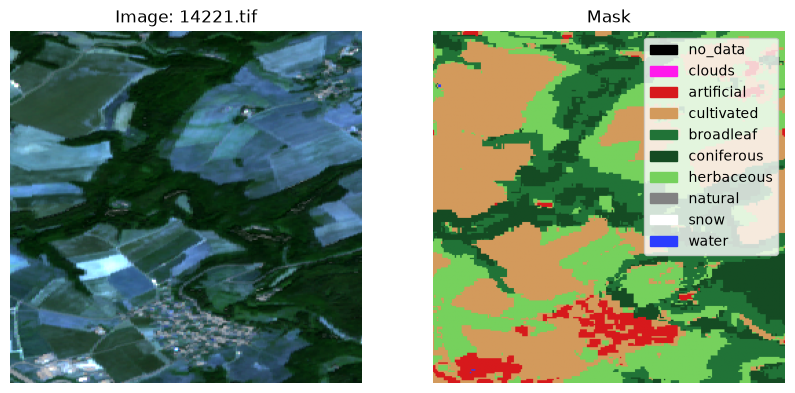

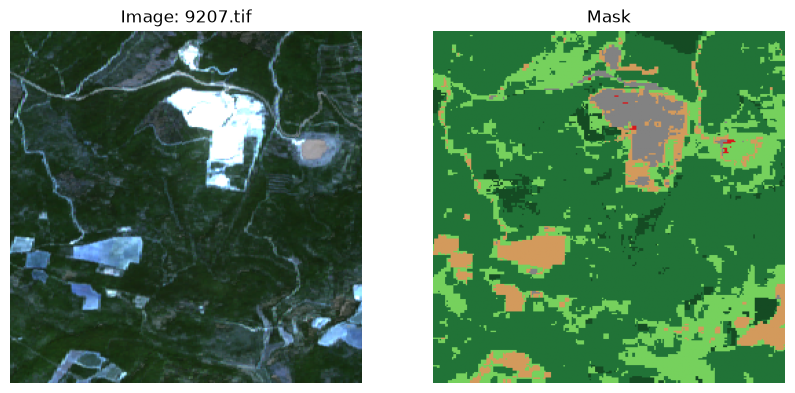

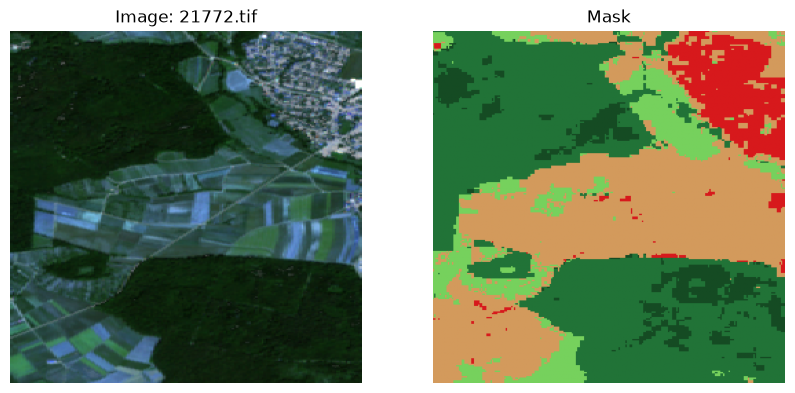

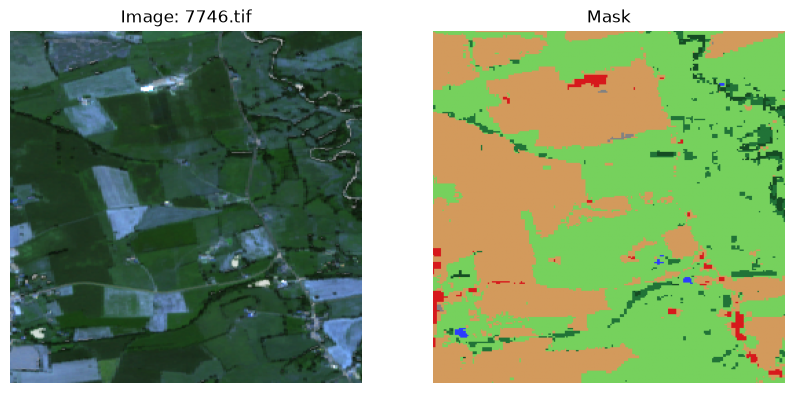

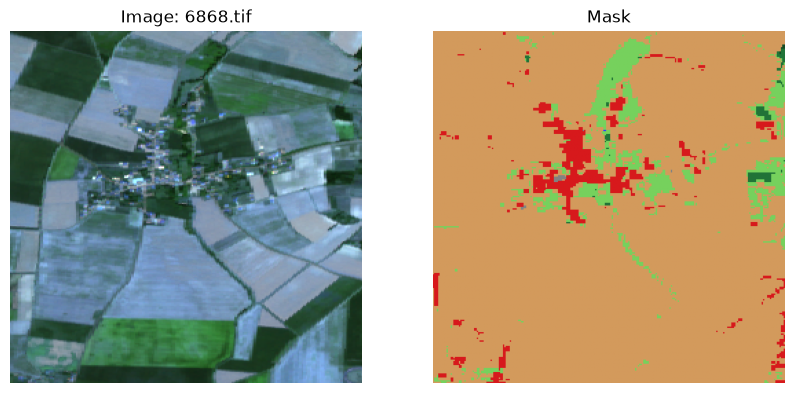

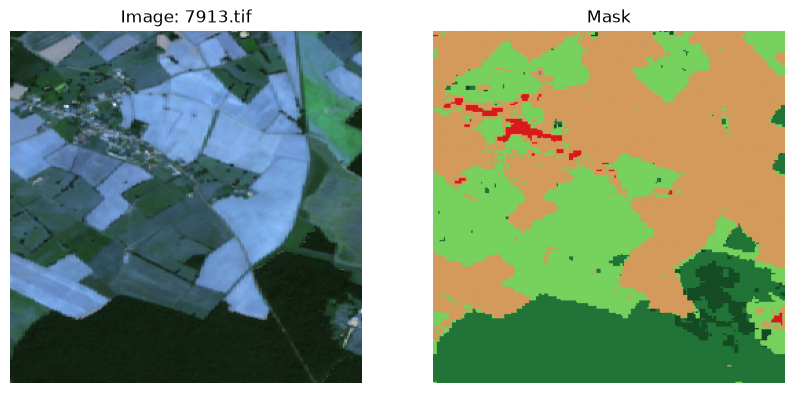

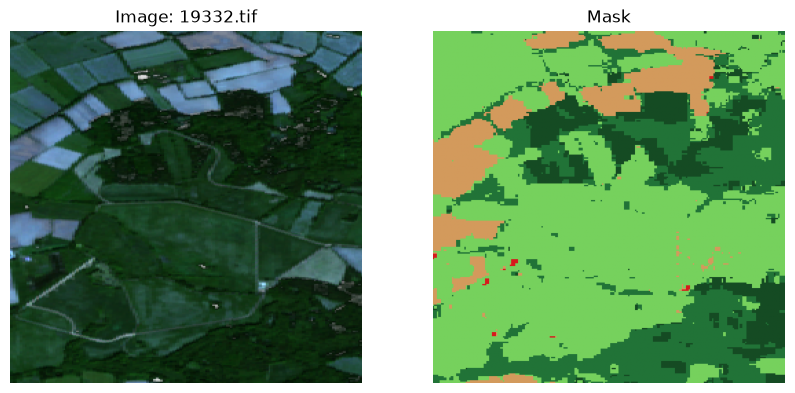

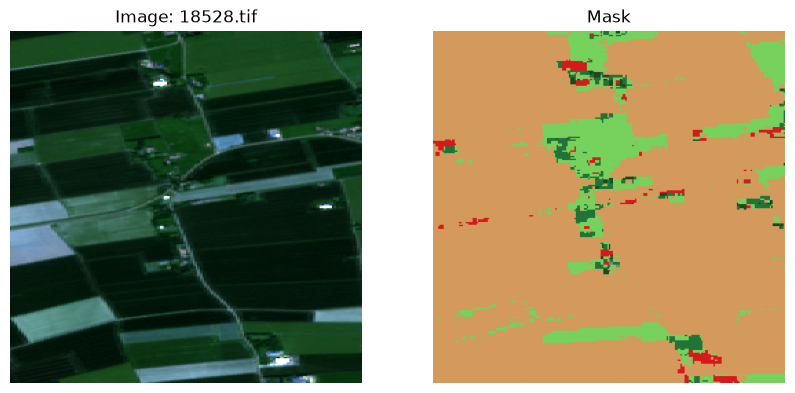

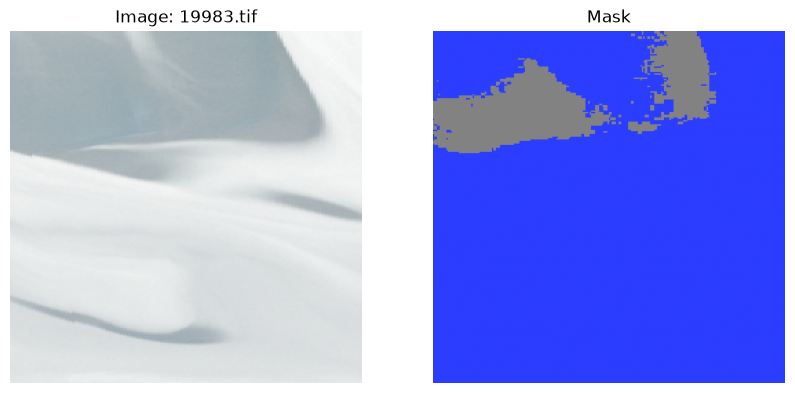

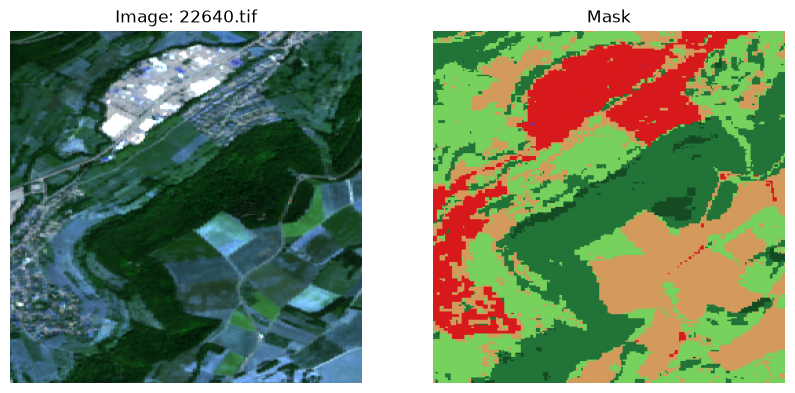

In [13]:
# Show 10 random (image, mask) pairs from the training set
for k, idx in enumerate(random.sample(range(len(train_images_paths)), 10)):
    image_path = train_images_paths[idx]
    mask_path = train_masks_paths[idx]
    assert image_path.name == mask_path.name
    
    with TiffFile(image_path) as tif:
        arr = tif.asarray()        
    fig, axs = plt.subplots(1, 2, figsize=(10, 10))
    show_image(arr, display_min=0, display_max=2200, ax=axs[0])
    
    with TiffFile(mask_path) as tif:
        arr = tif.asarray()
    classes_colorpalette = {c: color/255. for (c, color) in LCD.CLASSES_COLORPALETTE.items()} # LCD.CLASSES_COLORPALETTE.items()
    show_mask(arr,
              classes_colorpalette = classes_colorpalette,
              classes=LCD.CLASSES,  #LCD.CLASSES
              add_legend=(k == 0),
              ax=axs[1]
    )
    axs[0].set_title(f'Image: {image_path.name}')
    axs[1].set_title('Mask')
    #fig.tight_layout()

### Plot a few images from the training set

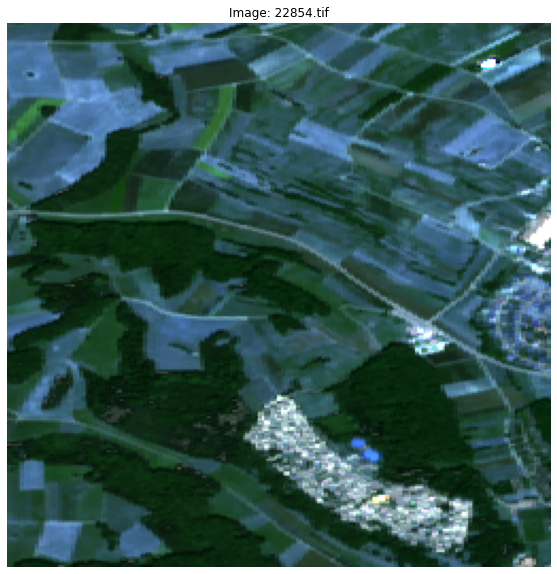

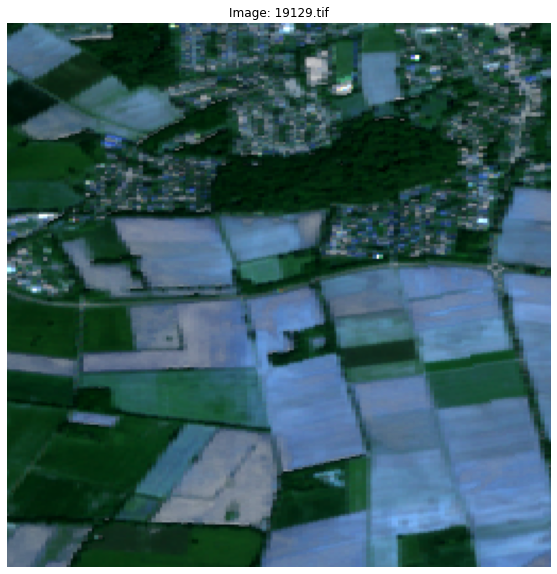

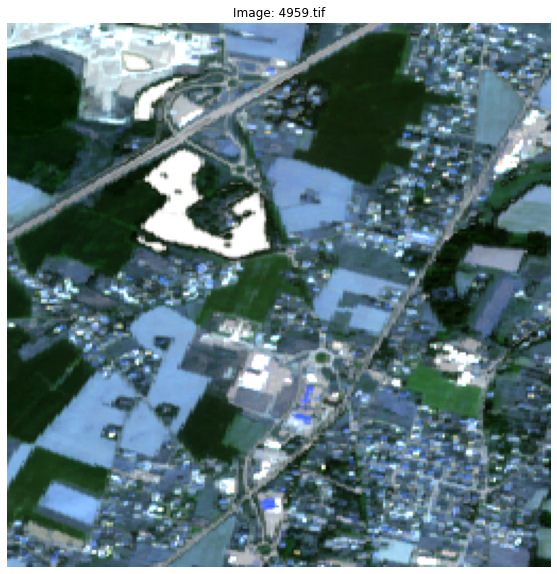

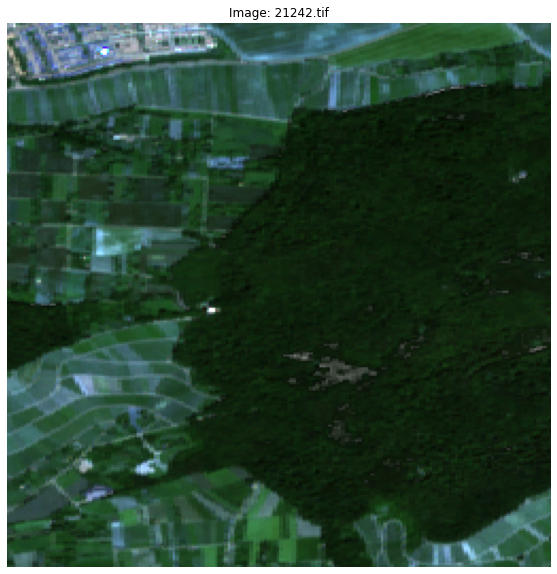

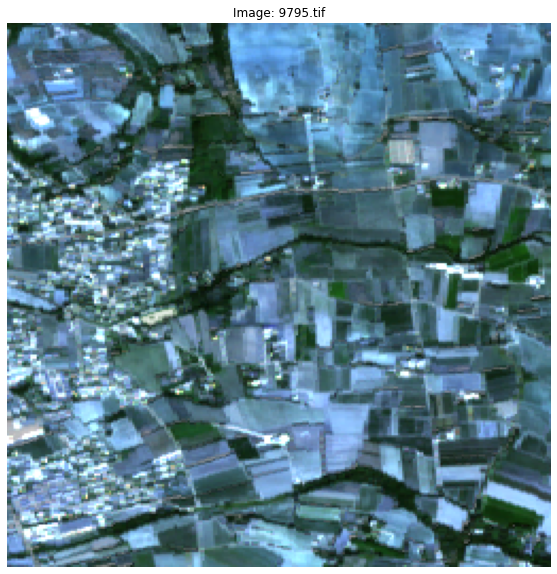

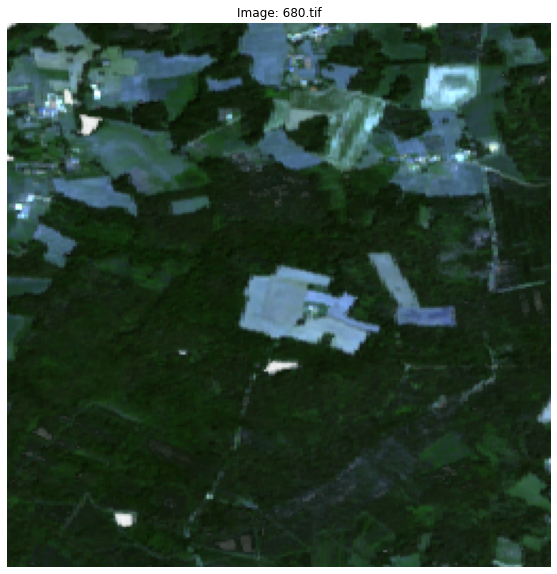

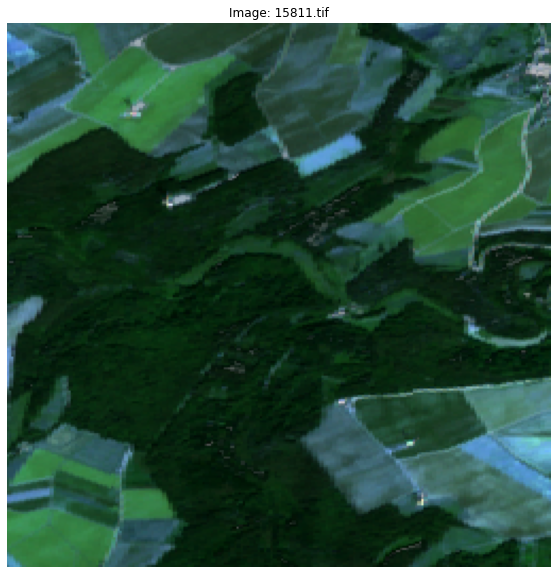

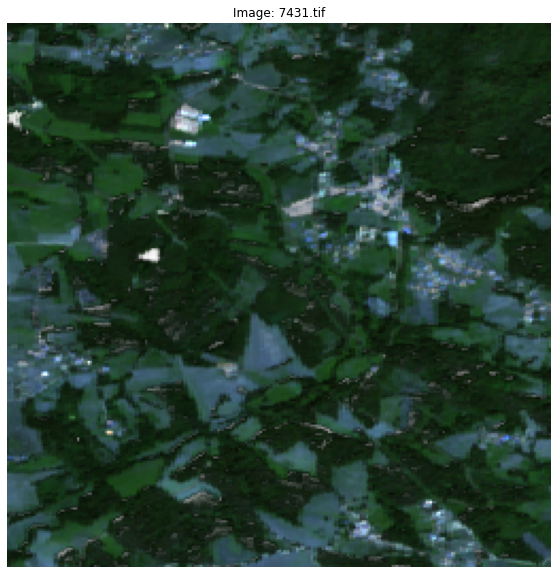

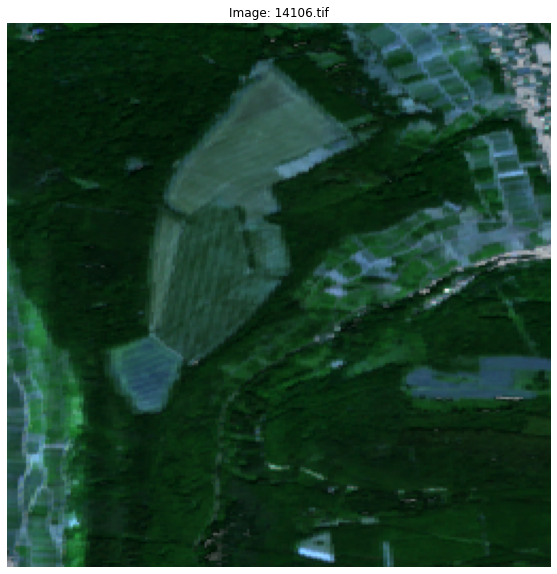

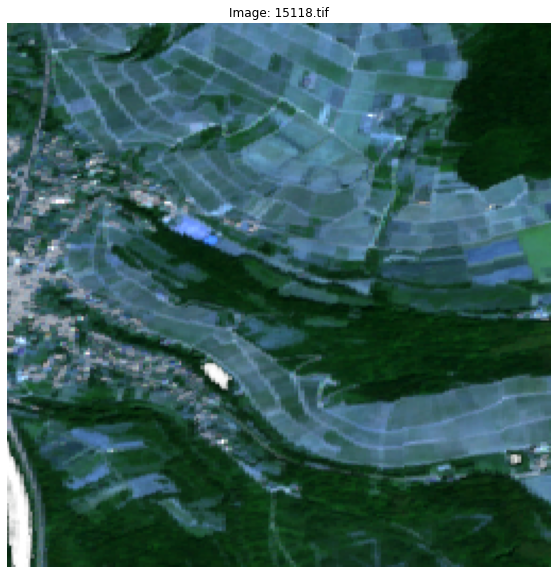

In [6]:
# Show 10 random images from the testing set
for idx in random.sample(range(len(test_images_paths)), 5):
    image_path = test_images_paths[idx]
    
    with TiffFile(image_path) as tif:
        arr = tif.asarray()        
    fig, ax = plt.subplots(figsize=(10, 10))
    show_image(arr, display_min=0, display_max=2200, ax=ax)
    
    ax.set_title(f'Image: {image_path.name}')
    #fig.tight_layout()

## Plot total class distribution in the training set

In [ ]:
# Compute total class distribution in train
def compute_class_counts(masks_paths, n_classes=10):
    """Return the cumulated class counts for all masks in the training set.
    Args:
        masks_paths (list[path-like]): paths to all masks 
    """
    cumcount = np.zeros((n_classes,), dtype=np.int64)
    for path in tqdm(masks_paths):
        with TiffFile(path) as tif:
            arr = tif.asarray()
            count = np.bincount(arr.ravel(), minlength=10)
            # hist, _ = np.histogram(arr, bins=n_classes, range=(0, 10)) # @todo: use bincount
            cumcount += count
    return cumcount
    
train_class_counts = compute_class_counts(train_masks_paths, n_classes=N_CLASSES ) #LCD.N_CLASSES
# this should be equal to LandCoverData.TRAIN_CLASS_COUNTS
assert (train_class_counts == LCD.TRAIN_CLASS_COUNTS ).all() #LCD.TRAIN_CLASS_COUNTS
# normalize to get a distribution
train_class_dist = train_class_counts / train_class_counts.sum()

100%|███████████████████████████████████████████████████████████████████████████| 18491/18491 [01:40<00:00, 184.41it/s]


In [10]:
def plot_class_distributions(class_counts, classes=None, class_colors=None):
    """Plot the proportion of the number of pixels for every class
    Args:
        class_counts (numpy.array): the raw class counts of shape (N_CLASSES,)
        classes (list[str], optional): list of class labels
        class_colors (numpy.array, optional): array of colors of shape (N_CLASSES, 3) in [0, 1]
    """
    rc_dict = { # font params for display
        'axes.titlesize': 19,
        'axes.labelsize': 16,
        'lines.linewidth': 2,
        'lines.markersize': 8,
        'font.size': 12,
        'xtick.labelsize': 12,
        'ytick.labelsize': 12
    }
    with plt.style.context(['seaborn', rc_dict]):
        class_dist = class_counts / class_counts.sum()
        fig, ax = plt.subplots(figsize=(12, 8))
        rects = ax.bar(range(len(class_dist)), class_dist, color=class_colors)
        ax.set_xticks(range(len(class_dist)))
        if classes is not None:
            ax.set_xticklabels(classes, rotation=90)
       
        for i, v in enumerate(class_counts):
            ax.text(i, class_dist[i] + 0.005, "{:.2e}".format(v))
        ax.set_xlabel("Classes")
        ax.set_ylabel("Proportion of the number of pixels")
        ax.set_title("Training set")

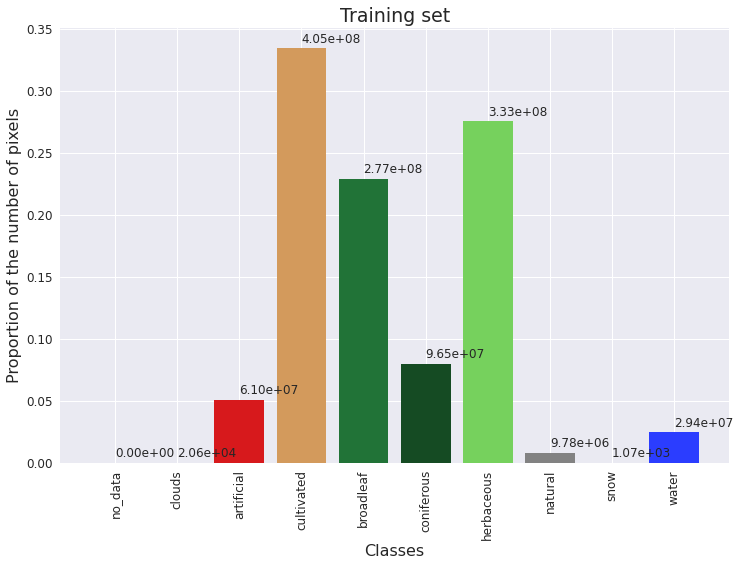

In [ ]:
plot_class_distributions(
    train_class_counts,
    classes=list(LCD.CLASSES), # LCD.CLASSES
    class_colors = np.asarray(list(CLASSES_COLORPALETTE.values()))/255. #LCD.CLASSES_COLORPALETTE
)

Nous observons un gros déséquilibre entre les classes, i.e. certains types de zones apparaissent très rarement sur les images contrairement à d'autres.

In [11]:
def read_image(path):

    with TiffFile(path) as t:
        img = t.asarray()

    if img.shape[-1] != LCD.N_CHANNELS and img.shape[0] == LCD.N_CHANNELS:
        img = np.transpose(img, (1, 2, 0))

    return img.astype(np.float32) / LCD.TRAIN_PIXELS_MAX



def read_mask(path) -> np.ndarray:
    """-> (H, W) int64"""
    with TiffFile(path) as t:
        return t.asarray().astype(np.int64)


def mask_path_from_image(image_path):
    return image_path.parent.parent / 'masks' / image_path.name

In [12]:
img = read_image(train_images_paths[0])

print("Shape :", img.shape)
print("Dtype :", img.dtype)
print("Min :", img.min())
print("Max :", img.max())
print("Mean :", img.mean())

Shape : (256, 256, 4)
Dtype : float32
Min : 4.1057647e-05
Max : 0.26654622
Mean : 0.05929845


In [13]:
class_values = {}

IGNORED_CLASSES_IDX = [0, 1]

for image_path in train_images_paths:

    img = read_image(image_path)
    mask = read_mask(mask_path_from_image(image_path))

    # Extraire les 4 bandes
    b2, b3, b4, b8 = (img[..., i] for i in range(4))


    # Créer un tableau de forme (H, W, 8)
    features = np.stack(
        [b2, b3, b4, b8],
        axis=-1
    )

    # Aplatir image et masque
    X = features.reshape(-1, 4)
    y = mask.ravel()

    # Exclure les classes ignorées
    valid = ~np.isin(y, LCD.IGNORED_CLASSES_IDX)

    X = X[valid]
    y = y[valid]

    # Regrouper les valeurs par classe
    for class_id in np.unique(y):

        pixels = X[y == class_id]

        if class_id not in class_values:
            class_values[class_id] = []

        class_values[class_id].append(pixels)


# Calcul des statistiques
results = []

feature_names = [
    "Blue", "Green", "Red", "NIR"
]

for class_id, arrays in class_values.items():

    pixels = np.concatenate(arrays, axis=0)

    for i, feature in enumerate(feature_names):

        results.append({
            "class": class_id,
            "feature": feature,
            "mean": np.mean(pixels[:, i]),
            "variance": np.var(pixels[:, i]),
            "std": np.std(pixels[:, i]),
        })

df = pd.DataFrame(results)

print(df.round(6))

    class feature      mean  variance       std
0       2    Blue  0.037058  0.000850  0.029163
1       2   Green  0.046529  0.000902  0.030026
2       2     Red  0.051860  0.001059  0.032538
3       2     NIR  0.096235  0.001114  0.033380
4       3    Blue  0.024753  0.000205  0.014305
5       3   Green  0.039386  0.000300  0.017309
6       3     Red  0.042035  0.000681  0.026087
7       3     NIR  0.137882  0.001251  0.035372
8       4    Blue  0.006092  0.000018  0.004205
9       4   Green  0.014929  0.000027  0.005204
10      4     Red  0.007485  0.000036  0.006002
11      4     NIR  0.153660  0.001138  0.033730
12      5    Blue  0.005563  0.000021  0.004592
13      5   Green  0.013158  0.000032  0.005658
14      5     Red  0.007574  0.000037  0.006082
15      5     NIR  0.109682  0.000881  0.029681
16      6    Blue  0.016533  0.000092  0.009579
17      6   Green  0.028991  0.000102  0.010109
18      6     Red  0.026662  0.000250  0.015827
19      6     NIR  0.136910  0.001263  0

In [14]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform

# Transformer le DataFrame :
# lignes = classes
# colonnes = features spectrales
mean_df = df.pivot(
    index="class",
    columns="feature",
    values="mean"
)

# Calcul des distances euclidiennes
distances = squareform(
    pdist(mean_df.values, metric="euclidean")
)

# Créer le DataFrame des distances
distance_df = pd.DataFrame(
    distances,
    index=mean_df.index,
    columns=mean_df.index
)

print("Moyennes par classe :")
print(mean_df.round(6))

print("\nMatrice des distances euclidiennes :")
print(distance_df.round(6))






Moyennes par classe :
feature      Blue     Green       NIR       Red
class                                          
2        0.037058  0.046529  0.096235  0.051860
3        0.024753  0.039386  0.137882  0.042035
4        0.006092  0.014929  0.153660  0.007485
5        0.005563  0.013158  0.109682  0.007574
6        0.016533  0.028991  0.136910  0.026662
7        0.036244  0.047565  0.073554  0.052494
8        0.083229  0.099964  0.111551  0.108735
9        0.015893  0.024031  0.020420  0.022218

Matrice des distances euclidiennes :
class         2         3         4         5         6         7         8  \
class                                                                         
2      0.000000  0.045094  0.084995  0.065174  0.054939  0.022728  0.091959   
3      0.045094  0.000000  0.048878  0.055127  0.020320  0.066682  0.110596   
4      0.084995  0.048878  0.000000  0.044016  0.030904  0.102064  0.158763   
5      0.065174  0.055127  0.044016  0.000000  0.038428  0.073812

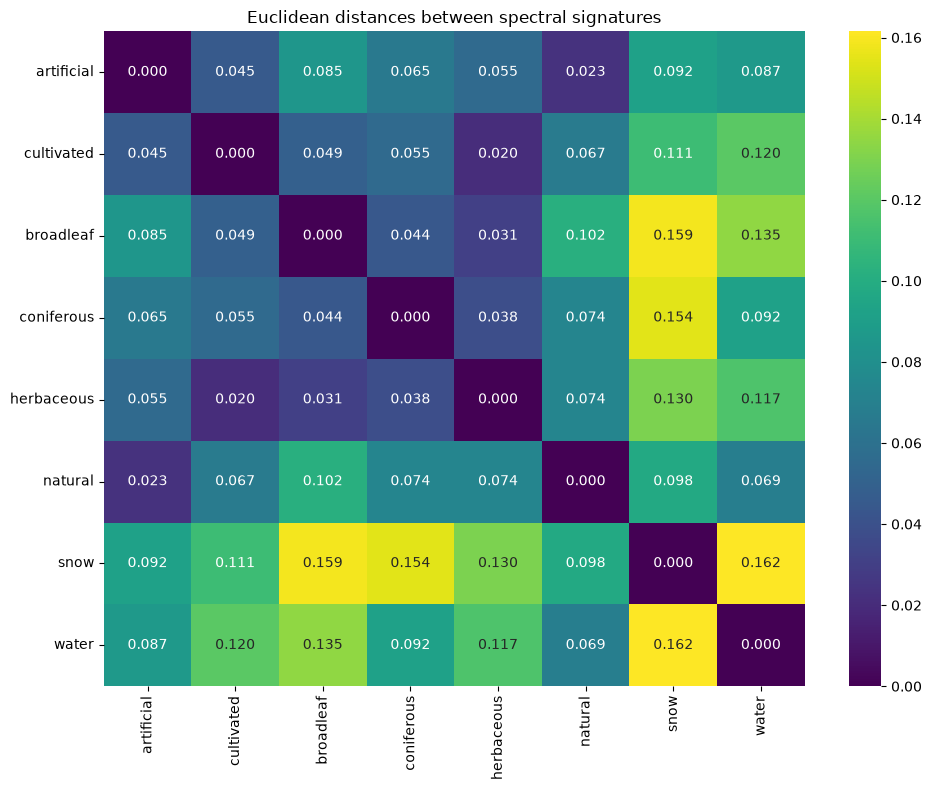

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
class_names = [LCD.CLASSES[int(c)] for c in mean_df.index]

# Afficher la heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    distances,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Euclidean distances between spectral signatures")
plt.tight_layout()
plt.show()
